In [1]:
from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
project_root = Path.cwd().parent

benchmark_root = project_root / "data" / "benchmark"
output_root = project_root / "results" / "images" / "preprocessing"

output_root.mkdir(parents=True, exist_ok=True)

print("Project:", project_root)
print("Benchmark:", benchmark_root)
print("Output:", output_root)

Project: D:\mycode\GlyphForge
Benchmark: D:\mycode\GlyphForge\data\benchmark
Output: D:\mycode\GlyphForge\results\images\preprocessing


In [3]:
categories = {
    "scanning": "Real5-OmniDocBench-Scanning",
    "warping": "Real5-OmniDocBench-Warping",
    "screen_photography": "Real5-OmniDocBench-Screen-Photography",
    "illumination": "Real5-OmniDocBench-Illumination",
    "skew": "Real5-OmniDocBench-Skew",
}

for name, folder in categories.items():
    folder_path = benchmark_root / folder
    files = sorted([
        file
        for file in folder_path.iterdir()
        if file.is_file() and file.suffix.lower() in {".png", ".jpg", ".jpeg", ".webp"}
    ])
    
    print(name, len(files))

scanning 5
warping 5
screen_photography 5
illumination 5
skew 5


In [4]:
selected_images = {}

for name, folder in categories.items():
    folder_path = benchmark_root / folder
    
    files = sorted([
        file
        for file in folder_path.iterdir()
        if file.is_file() and file.suffix.lower() in {".png", ".jpg", ".jpeg", ".webp"}
    ])
    
    if not files:
        raise FileNotFoundError(f"No images found in {folder_path}")
    
    selected_images[name] = files[0]

for category, path in selected_images.items():
    print(category, "->", path.name)

scanning -> PPT_1001115_eng_page_003.png
warping -> PPT_1001115_eng_page_003.png
screen_photography -> PPT_1001115_eng_page_003.png
illumination -> PPT_1001115_eng_page_003.png
skew -> PPT_1001115_eng_page_003.png


In [5]:
images = {}

for category, path in selected_images.items():
    image = cv2.imread(str(path))
    
    if image is None:
        raise ValueError(f"Could not load {path}")
    
    images[category] = image
    
    print(
        category,
        "|",
        image.shape,
        "|",
        round(path.stat().st_size / 1024, 2),
        "KB"
    )

scanning | (1186, 1677, 3) | 438.93 KB
warping | (2160, 3840, 3) | 6656.04 KB
screen_photography | (2160, 3840, 3) | 10873.0 KB
illumination | (2160, 3840, 3) | 5778.42 KB
skew | (3072, 4096, 3) | 13509.62 KB


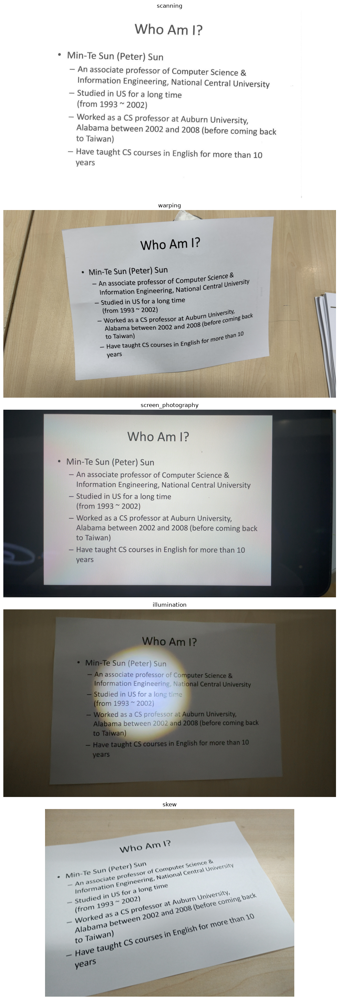

In [6]:
fig, axes = plt.subplots(5, 1, figsize=(16, 30))

for ax, (category, image) in zip(axes, images.items()):
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    ax.imshow(image_rgb)
    ax.set_title(category)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
def to_grayscale(image):
    return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [8]:
def denoise(image):
    return cv2.GaussianBlur(image, (5, 5), 0)

In [9]:
def otsu_threshold(image):
    threshold, binary = cv2.threshold(
        image,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    
    return binary, threshold

In [10]:
def adaptive_threshold(image):
    return cv2.adaptiveThreshold(
        image,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        31,
        10
    )

In [11]:
def morphological_cleanup(binary):
    kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT,
        (2, 2)
    )
    
    return cv2.morphologyEx(
        binary,
        cv2.MORPH_OPEN,
        kernel
    )

In [12]:
def deskew(binary):
    inverted = cv2.bitwise_not(binary)
    coordinates = np.column_stack(np.where(inverted > 0))
    
    if len(coordinates) < 10:
        return binary, 0.0
    
    rect = cv2.minAreaRect(coordinates.astype(np.float32))
    angle = rect[-1]
    
    if angle < -45:
        angle = -(90 + angle)
    else:
        angle = -angle
    
    height, width = binary.shape[:2]
    center = (width / 2, height / 2)
    
    matrix = cv2.getRotationMatrix2D(
        center,
        angle,
        1.0
    )
    
    rotated = cv2.warpAffine(
        binary,
        matrix,
        (width, height),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=255
    )
    
    return rotated, angle

In [13]:
def preprocess(image):
    grayscale = to_grayscale(image)
    denoised = denoise(grayscale)
    otsu, threshold_value = otsu_threshold(denoised)
    cleaned = morphological_cleanup(otsu)
    corrected, angle = deskew(cleaned)
    
    return {
        "grayscale": grayscale,
        "denoised": denoised,
        "otsu": otsu,
        "cleaned": cleaned,
        "deskewed": corrected,
        "otsu_threshold": threshold_value,
        "deskew_angle": angle,
    }

In [14]:
processed = {}

for category, image in images.items():
    processed[category] = preprocess(image)
    
    print(
        category,
        "| Otsu:",
        round(float(processed[category]["otsu_threshold"]), 2),
        "| Deskew:",
        round(float(processed[category]["deskew_angle"]), 2)
    )

scanning | Otsu: 188.0 | Deskew: -2.66
warping | Otsu: 129.0 | Deskew: -90.0
screen_photography | Otsu: 121.0 | Deskew: -90.0
illumination | Otsu: 125.0 | Deskew: -90.0
skew | Otsu: 173.0 | Deskew: -90.0


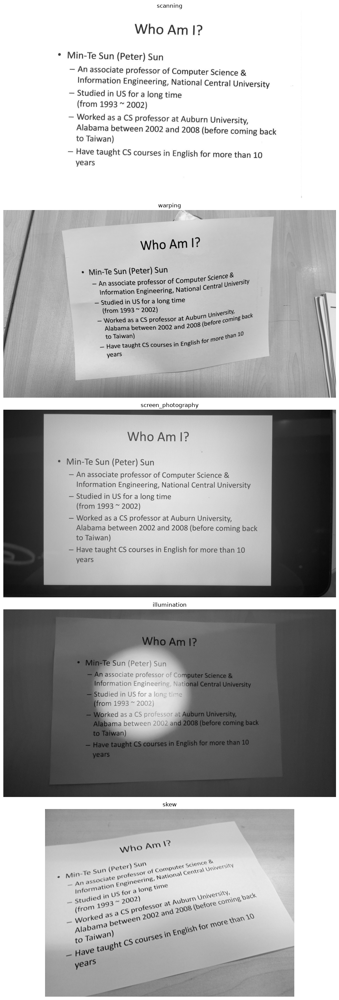

In [15]:
fig, axes = plt.subplots(5, 1, figsize=(16, 30))

for ax, category in zip(axes, processed):
    ax.imshow(
        processed[category]["grayscale"],
        cmap="gray"
    )
    ax.set_title(category)
    ax.axis("off")

plt.tight_layout()
plt.show()

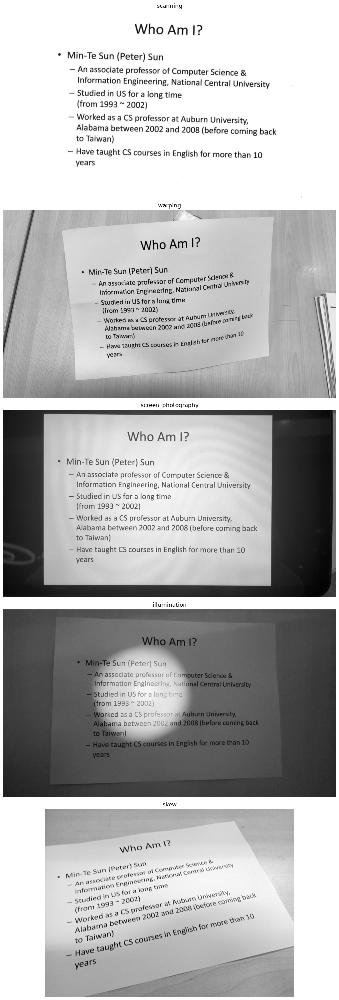

In [16]:
fig, axes = plt.subplots(5, 1, figsize=(16, 30))

for ax, category in zip(axes, processed):
    ax.imshow(
        processed[category]["denoised"],
        cmap="gray"
    )
    ax.set_title(category)
    ax.axis("off")

plt.tight_layout()
plt.show()

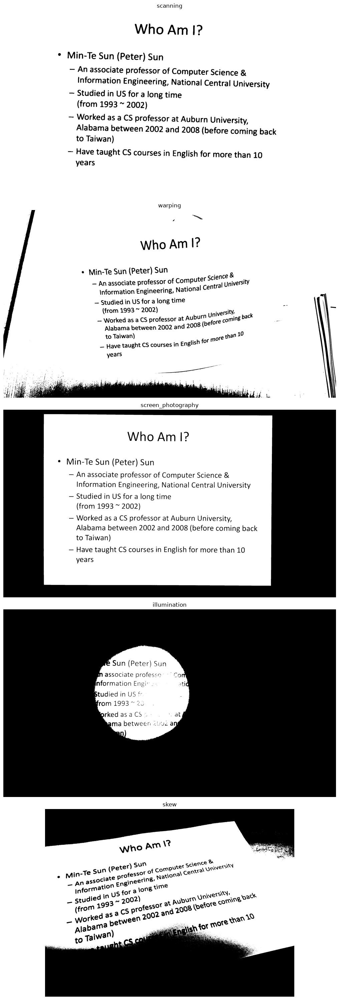

In [17]:
fig, axes = plt.subplots(5, 1, figsize=(16, 30))

for ax, category in zip(axes, processed):
    ax.imshow(
        processed[category]["otsu"],
        cmap="gray"
    )
    ax.set_title(category)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:
adaptive_results = {}

for category, data in processed.items():
    adaptive_results[category] = adaptive_threshold(
        data["denoised"]
    )

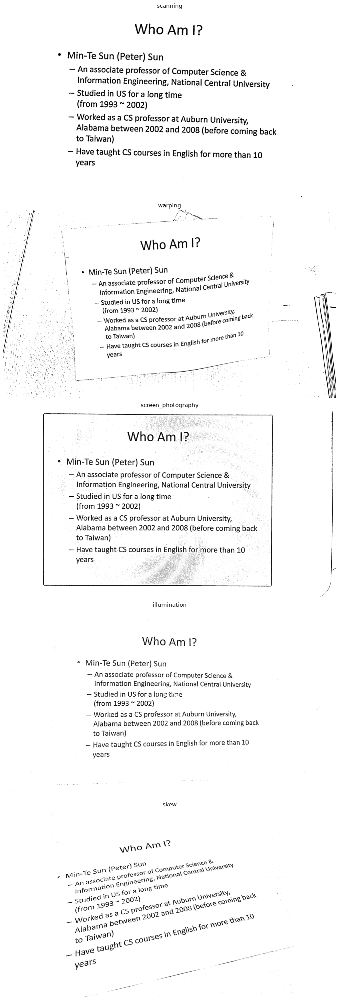

In [19]:
fig, axes = plt.subplots(5, 1, figsize=(16, 30))

for ax, category in zip(axes, adaptive_results):
    ax.imshow(
        adaptive_results[category],
        cmap="gray"
    )
    ax.set_title(category)
    ax.axis("off")

plt.tight_layout()
plt.show()

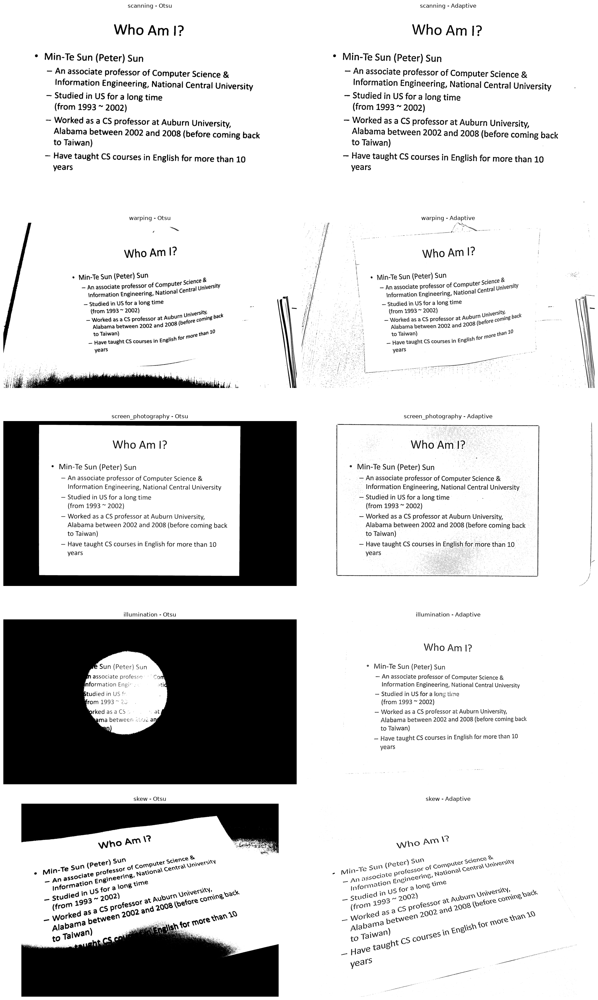

In [20]:
fig, axes = plt.subplots(5, 2, figsize=(18, 30))

for row, category in enumerate(processed):
    axes[row, 0].imshow(
        processed[category]["otsu"],
        cmap="gray"
    )
    axes[row, 0].set_title(f"{category} - Otsu")
    axes[row, 0].axis("off")
    
    axes[row, 1].imshow(
        adaptive_results[category],
        cmap="gray"
    )
    axes[row, 1].set_title(f"{category} - Adaptive")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

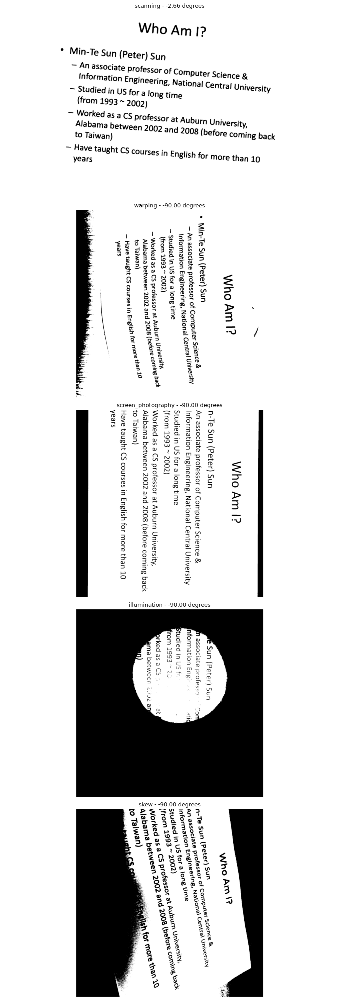

In [21]:
fig, axes = plt.subplots(5, 1, figsize=(16, 30))

for ax, category in zip(axes, processed):
    ax.imshow(
        processed[category]["deskewed"],
        cmap="gray"
    )
    ax.set_title(
        f"{category} - {processed[category]['deskew_angle']:.2f} degrees"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [22]:
for category, data in processed.items():
    category_output = output_root / category
    category_output.mkdir(parents=True, exist_ok=True)
    
    cv2.imwrite(
        str(category_output / "grayscale.png"),
        data["grayscale"]
    )
    
    cv2.imwrite(
        str(category_output / "denoised.png"),
        data["denoised"]
    )
    
    cv2.imwrite(
        str(category_output / "otsu.png"),
        data["otsu"]
    )
    
    cv2.imwrite(
        str(category_output / "cleaned.png"),
        data["cleaned"]
    )
    
    cv2.imwrite(
        str(category_output / "deskewed.png"),
        data["deskewed"]
    )
    
    cv2.imwrite(
        str(category_output / "adaptive.png"),
        adaptive_results[category]
    )

In [23]:
records = []

for category, original in images.items():
    original_path = selected_images[category]
    
    representations = {
        "original": original,
        "grayscale": processed[category]["grayscale"],
        "denoised": processed[category]["denoised"],
        "otsu": processed[category]["otsu"],
        "adaptive": adaptive_results[category],
        "cleaned": processed[category]["cleaned"],
        "deskewed": processed[category]["deskewed"],
    }
    
    original_size = original_path.stat().st_size
    
    for method, representation in representations.items():
        if method == "original":
            size_bytes = original_size
        else:
            category_output = output_root / category
            
            if method == "grayscale":
                path = category_output / "grayscale.png"
            elif method == "denoised":
                path = category_output / "denoised.png"
            elif method == "otsu":
                path = category_output / "otsu.png"
            elif method == "adaptive":
                path = category_output / "adaptive.png"
            elif method == "cleaned":
                path = category_output / "cleaned.png"
            elif method == "deskewed":
                path = category_output / "deskewed.png"
            
            size_bytes = path.stat().st_size
        
        records.append({
            "category": category,
            "document": original_path.name,
            "method": method,
            "size_bytes": size_bytes,
            "size_kb": size_bytes / 1024,
            "compression_ratio": original_size / size_bytes,
            "width": representation.shape[1],
            "height": representation.shape[0],
            "channels": 1 if representation.ndim == 2 else representation.shape[2],
        })

preprocessing_results = pd.DataFrame(records)

preprocessing_results

,category,document,method,size_bytes,size_kb,compression_ratio,width,height,channels
0,scanning,PPT_1001115_eng_page_003.png,original,449460,438.925781,1.000000,1677,1186,3
1,scanning,PPT_1001115_eng_page_003.png,grayscale,278192,271.671875,1.615647,1677,1186,1
2,scanning,PPT_1001115_eng_page_003.png,denoised,270096,263.765625,1.664075,1677,1186,1
3,scanning,PPT_1001115_eng_page_003.png,otsu,43976,42.945312,10.220575,1677,1186,1
4,scanning,PPT_1001115_eng_page_003.png,adaptive,46008,44.929688,9.769171,1677,1186,1
5,scanning,PPT_1001115_eng_page_003.png,cleaned,43852,42.824219,10.249476,1677,1186,1
6,scanning,PPT_1001115_eng_page_003.png,deskewed,129475,126.440430,3.471404,1677,1186,1
7,warping,PPT_1001115_eng_page_003.png,original,6815788,6656.042969,1.000000,3840,2160,3
8,warping,PPT_1001115_eng_page_003.png,grayscale,3898795,3807.416992,1.748178,3840,2160,1
9,warping,PPT_1001115_eng_page_003.png,denoised,2862813,2795.715820,2.380801,3840,2160,1


In [24]:
preprocessing_results.sort_values(
    ["category", "compression_ratio"],
    ascending=[True, False]
).reset_index(drop=True)

,category,document,method,size_bytes,size_kb,compression_ratio,width,height,channels
0,illumination,PPT_1001115_eng_page_003.png,cleaned,41442,40.470703,142.780295,3840,2160,1
1,illumination,PPT_1001115_eng_page_003.png,otsu,41587,40.612305,142.282468,3840,2160,1
2,illumination,PPT_1001115_eng_page_003.png,deskewed,46063,44.983398,128.456701,3840,2160,1
3,illumination,PPT_1001115_eng_page_003.png,adaptive,83151,81.202148,71.160912,3840,2160,1
4,illumination,PPT_1001115_eng_page_003.png,denoised,2546666,2486.978516,2.323470,3840,2160,1
5,illumination,PPT_1001115_eng_page_003.png,grayscale,3147266,3073.501953,1.880077,3840,2160,1
6,illumination,PPT_1001115_eng_page_003.png,original,5917101,5778.418945,1.000000,3840,2160,3
7,scanning,PPT_1001115_eng_page_003.png,cleaned,43852,42.824219,10.249476,1677,1186,1
8,scanning,PPT_1001115_eng_page_003.png,otsu,43976,42.945312,10.220575,1677,1186,1
9,scanning,PPT_1001115_eng_page_003.png,adaptive,46008,44.929688,9.769171,1677,1186,1


In [25]:
preprocessing_results_path = (
    project_root
    / "results"
    / "benchmarks"
    / "preprocessing_baseline.csv"
)

preprocessing_results.to_csv(
    preprocessing_results_path,
    index=False
)

print(preprocessing_results_path)

D:\mycode\GlyphForge\results\benchmarks\preprocessing_baseline.csv


In [26]:
preprocessing_results.groupby(
    "method"
)["size_kb"].mean().sort_values()

method
cleaned        91.724414
otsu           93.456641
deskewed       98.834180
adaptive      114.310156
denoised     2682.095898
grayscale    3897.398438
original     7451.201172
Name: size_kb, dtype: float64

In [27]:
preprocessing_results.groupby(
    "method"
)["compression_ratio"].mean().sort_values(
    ascending=False
)

method
deskewed     85.470749
cleaned      82.385245
otsu         81.421558
adaptive     59.200880
denoised      2.518728
grayscale     1.842893
original      1.000000
Name: compression_ratio, dtype: float64

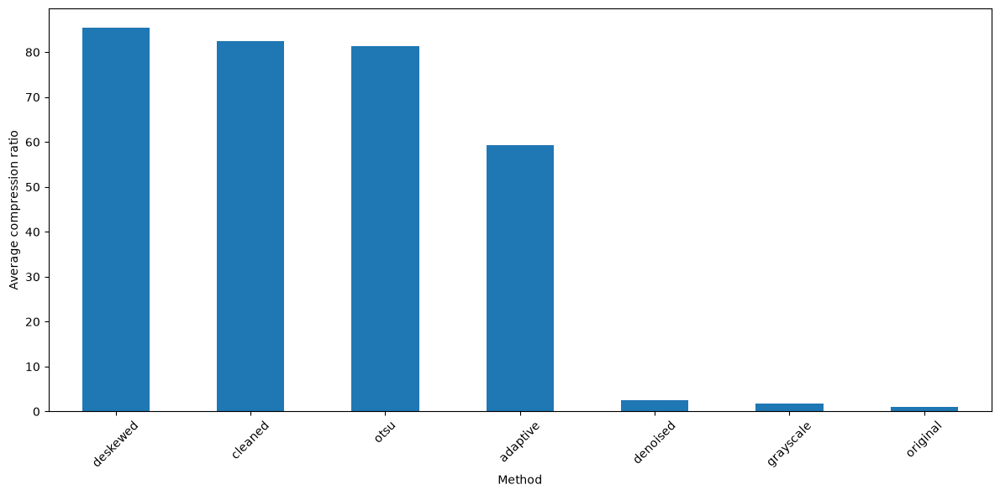

In [28]:
compression_summary = (
    preprocessing_results
    .groupby("method")["compression_ratio"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
compression_summary.plot(kind="bar")
plt.ylabel("Average compression ratio")
plt.xlabel("Method")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
print("Notebook 02 complete")
print("Documents processed:", len(images))
print("Representations tested:", len(preprocessing_results["method"].unique()))

Notebook 02 complete
Documents processed: 5
Representations tested: 7
